In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [103]:
df = pd.read_csv('titanic_cleaned.csv')

df

,survived,pclass,sex,age,sibsp,parch,fare,who,embark_town,alone
0,0,3,male,22.0,1,0,7.2500,man,Southampton,0
1,1,1,female,38.0,1,0,71.2833,woman,Cherbourg,0
2,1,3,female,26.0,0,0,7.9250,woman,Southampton,1
3,1,1,female,35.0,1,0,53.1000,woman,Southampton,0
4,0,3,male,35.0,0,0,8.0500,man,Southampton,1
...,...,...,...,...,...,...,...,...,...,...
779,0,3,female,39.0,0,5,29.1250,woman,Queenstown,0
780,1,1,female,19.0,0,0,30.0000,woman,Southampton,1
781,0,3,female,24.0,1,2,23.4500,woman,Southampton,0
782,1,1,male,26.0,0,0,30.0000,man,Cherbourg,1


# 1. Survival Rate by Passenger Class (`pclass`)

Ticket class tells us about a passenger's wealth and where their cabin was located on the ship. Let's look at the survival numbers for 1st, 2nd, and 3rd class to see if wealthier passengers had a better chance of getting into a lifeboat.

In [104]:
survivors = df[df['survived'] == 1].groupby('pclass')['survived'].count().reset_index()
survivors

,pclass,survived
0,1,135
1,2,84
2,3,104


In [105]:
class_totals = df.groupby('pclass')['survived'].count().reset_index(name='total_class_passengers')
class_totals

,pclass,total_class_passengers
0,1,214
1,2,165
2,3,405


In [106]:
survivors = pd.merge(survivors, class_totals, on='pclass')
survivors

,pclass,survived,total_class_passengers
0,1,135,214
1,2,84,165
2,3,104,405


In [107]:
survivors['survival_rate_pct'] = (survivors['survived'] / survivors['total_class_passengers']) * 100
survivors

,pclass,survived,total_class_passengers,survival_rate_pct
0,1,135,214,63.084112
1,2,84,165,50.909091
2,3,104,405,25.679012


C:\Users\User\AppData\Local\Temp\ipykernel_19340\2407437720.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='pclass', y='survived', errorbar=None, palette='Blues_d')


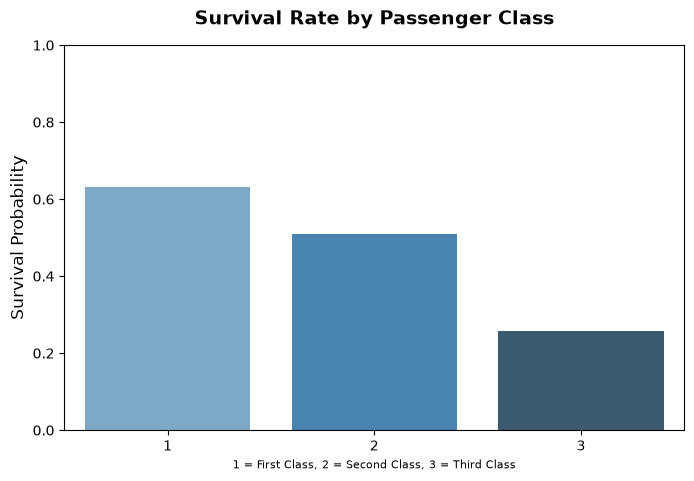

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='pclass', y='survived', errorbar=None, palette='Blues_d')
plt.title('Survival Rate by Passenger Class', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('1 = First Class, 2 = Second Class, 3 = Third Class', fontsize=8)
plt.ylabel('Survival Probability', fontsize=12)
plt.ylim(0, 1)
plt.show()

### Insights

* **First Class Had the Best Odds:** Passengers in 1st class had a survival rate of over 60%, giving them the highest chance of making it onto a lifeboat.
* **Second Class Dropped to Even:** Passengers in 2nd class had about a 50% chance of survival. 
* **Third Class Faced the Hardest Odds:** 3rd class passengers had the lowest survival rate at roughly 25%, showing a clear gap in survival chances based on ticket class and ship location.

# 2. Survival Rate by Gender and Demographic (`sex` / `who`)

Historical accounts emphasize the evacuation policy prioritizing women and children. Let's analyze the survival breakdown by gender to quantify this effect.

In [109]:
sex_survivors = df[df['survived'] == 1].groupby('sex')['survived'].count().reset_index(name='survivor_count')
sex_survivors

,sex,survivor_count
0,female,217
1,male,106


In [110]:
sex_totals = df.groupby('sex')['survived'].count().reset_index(name='total_count')
sex_totals

,sex,total_count
0,female,293
1,male,491


In [111]:
sex_summary = pd.merge(sex_totals, sex_survivors, on='sex')
sex_summary

,sex,total_count,survivor_count
0,female,293,217
1,male,491,106


In [112]:
sex_summary['survival_rate_pct'] = (sex_summary['survivor_count'] / sex_summary['total_count']) * 100
sex_summary

,sex,total_count,survivor_count,survival_rate_pct
0,female,293,217,74.061433
1,male,491,106,21.588595


C:\Users\User\AppData\Local\Temp\ipykernel_19340\1386174820.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='sex', y='survived', errorbar=None, palette='Set2')


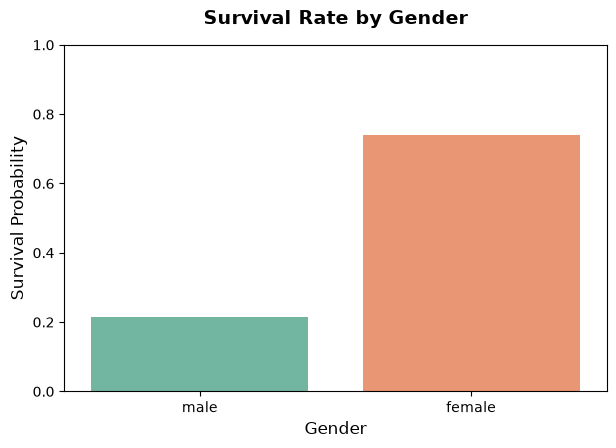

In [113]:
plt.figure(figsize=(7, 4.5))
sns.barplot(data=df, x='sex', y='survived', errorbar=None, palette='Set2')
plt.title('Survival Rate by Gender', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Survival Probability', fontsize=12)
plt.ylim(0, 1)
plt.show()

### Insights

* **Women Had a Much Higher Chance of Survival:** Roughly 74% of female passengers survived, showing that women were strongly prioritized for lifeboats.
* **Men Faced Very Low Odds:** Only about 21% of male passengers survived, meaning men were more than three times less likely to survive than women.
* **Strongest Single Factor:** Gender shows an even bigger gap in survival rates than passenger class, proving how strictly the "women and children first" rule was followed during the rescue.

# 3. Age Distribution Analysis (Survivors vs. Non-Survivors)

Everyone knows the famous "women and children first" rule from the Titanic. To check if this actually happened in the data, we separate the passengers who survived from those who didn't, and compare their ages.

In [118]:
survivor_ages = df[df['survived'] == 1]['age']
print(f"Mean Age of Survivors: {survivor_ages.mean()}")
print(f"Median Age of Survivors: {survivor_ages.median()}")

Mean Age of Survivors: 28.464148606811147
Median Age of Survivors: 28.0


In [119]:
non_survivor_ages = df[df['survived'] == 0]['age']
print(f"Mean Age of Non-Survivors: {non_survivor_ages.mean()}")
print(f"Median Age of Non-Survivors: {non_survivor_ages.median()}")

Mean Age of Non-Survivors: 30.387201735357916
Median Age of Non-Survivors: 28.0


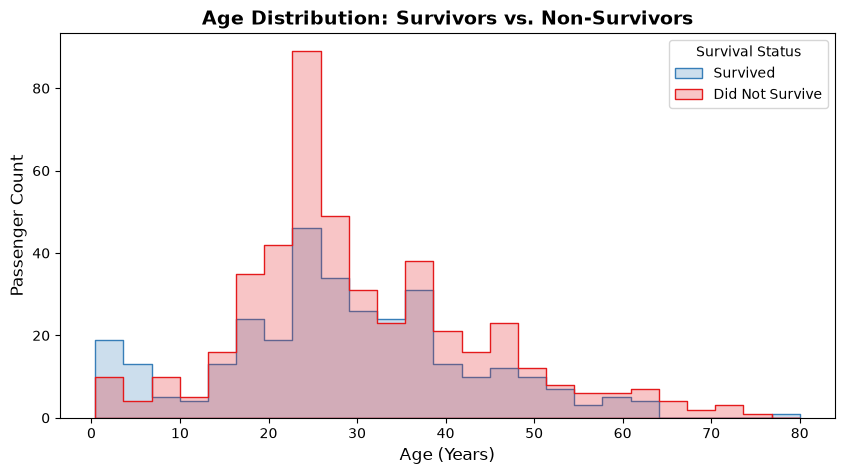

In [128]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='age', hue='survived', element='step', palette='Set1')
plt.title('Age Distribution: Survivors vs. Non-Survivors', fontsize=14, fontweight='bold')
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Passenger Count', fontsize=12)
plt.legend(title='Survival Status', labels=['Survived', 'Did Not Survive'], loc='upper right')
plt.show()

### Insights
* **Young Children Were Saved First:** For kids under 6 years old, more children survived than died. This shows that crew members worked hard to put young children into lifeboats first.
* **Young Adults Suffered the Most:** Most people on the ship were between 20 and 30 years old, and this group had the highest number of deaths.
* **Very Few Older Survivors:** Passengers over 60 years old had a much harder time surviving, with almost no survivors over age 65 except for one person around age 80.

# Conclusion

Based on our exploratory data analysis of the Titanic dataset, we can draw three major conclusions regarding passenger survival:

1. **Gender Was the Strongest Lifeline:** The historical "women and children first" protocol was heavily enforced. Female passengers experienced a dramatically higher survival rate (~74%) compared to male passengers (~21%).
2. **Socioeconomic Status Mattered:** Passenger class played a critical role. First-class passengers enjoyed over a 60% survival rate, while third-class passengers faced the steepest hurdles with only about a 25% survival rate, largely due to ship layout and evacuation logistics.
3. **Age Priority for the Youngest:** Infants and young children (ages 0–6) showed a clear survival advantage, confirming that crew efforts successfully prioritized toddlers during rescue operations. Meanwhile, young adults (ages 20–30) suffered the highest absolute number of casualties due to their high representation in third class and among male travelers.